# Distance, path shape and trials per session

`occupancy_uniformity.ipynb` found that within a mouse, sessions with more trials have slightly more uniform search, but the index barely moves (0.92-0.99), and the relation is weak in the vision sessions. This notebook asks the same question of other measures, first **how far the mouse travels**, then the **path-shape measures** of `search_trajectories.ipynb`, and compares how closely each tracks trials per session.

`search_trajectories.ipynb` (section 4) already showed that on a good day a mouse covers more ground (within-mouse r = 0.64 with total session distance in odor, 0.62 in vision). Here distance is split, because part of the link with trials is built in:

- **session distance**: the whole session, searching or not.
- **search distance**: only while searching, from the start of each trial to the moment its target is found.
- **other distance**: the rest. Every trial adds a walk to the port and back, so this part grows with trials by construction.
- **search distance per trial**: search distance divided by trials, the path the mouse needs per target.
- **search speed**: search distance divided by search time, the ground covered per second of searching. Unlike the others, nothing ties it to the trial count by construction.

Search distance and trials are also tied by arithmetic: search distance = trials x path per trial. How far the first follows the second says how much of a good session is the mouse covering more ground, and how much is it needing less ground per target.

**Path-shape measures**, exactly as defined in `search_trajectories.ipynb`: share of search time moving, speed while moving, turning, straightness, share of path along the walls, and yield (new cells checked per 1000 px). Search speed above is the product of the first two. These are **phase-matched**: a search gets slower and more tortuous the longer it lasts, and sessions with few trials have more long searches, so each measure is computed within each phase of a search (0-4 s, 4-10 s, 10-25 s, over 25 s) and the phases are averaged with the same weights for every session. Without this, a session with fewer trials would look more tortuous for that reason alone.

**Distances** are on the SLEAP body centroid, lightly smoothed, from `output/trajectories*.csv` and `output/sessions*.csv`, in camera pixels (the arena is 888 x 1968 px; there is no calibration to cm). **Trials per session** is the number of completed trials (targets found), as in the occupancy notebooks.

**The regression** is the one used for uniformity: the measure is the outcome, trials the predictor, fitted within each mouse and summarised across mice. Distances are fitted as logs, so the slope is an **elasticity**: the percent change in distance for a 1% change in trials. To compare measures with different units, the table also gives the within-mouse correlation (r).

Odor `x` and vision `v` sessions, each mouse's first ten of each (mouse 9000 has six vision sessions).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials
from src.trajectories import load_trajectories, load_sessions     # run `python -m src.trajectories` to rebuild output/trajectories*.csv
from src.occupancy import load_occupancy, X_EDGES, Y_EDGES       # run `python -m src.occupancy` to rebuild output/occupancy*.npz

pd.set_option('display.width', 200, 'display.precision', 3)

EXPERIMENTS = ['odor', 'vision']
EXP_COLOR = {'odor': '#2a78d6', 'vision': '#7a52c7'}
EXP_LABEL = {'odor': 'Odor', 'vision': 'Vision'}
from src.style import INK, MUTED, GRID, PAPER, use_style
use_style()
KEYS = ['experiment', 'mouse', 'session']

trials = pd.concat([load_trials(e).assign(experiment=e) for e in EXPERIMENTS]).groupby(KEYS).size().rename('trials')
search = pd.concat([load_trajectories(e) for e in EXPERIMENTS]).groupby(KEYS).agg(search_px=('path_px', 'sum'), search_s=('search_s', 'sum'))
ses = pd.concat([load_sessions(e) for e in EXPERIMENTS]).set_index(KEYS).join([trials, search]).reset_index()
ses = ses.sort_values(['experiment', 'mouse', 'session_num'], ignore_index=True)
ses['session_px'] = ses.total_path_px
ses['other_px'] = ses.session_px - ses.search_px
ses['px_per_trial'] = ses.search_px / ses.trials
ses['px_per_s'] = ses.search_px / ses.search_s

# path-shape measures, phase-matched as in search_trajectories.ipynb: each a ratio of two sums, computed within search phase
# and averaged over phases with the same weights for every session
TRAJ_DEF = {'moving':       ('share of time moving', 'moving_s', 'search_s', 1),
            'speed_moving': ('speed while moving (px/s)', 'path_px', 'moving_s', 1),
            'turning':      ('turning (deg per 40 px)', 'turn_sum', 'turn_n', 180 / np.pi),
            'straightness': ('straightness (480 px)', 'straight_sum', 'straight_n', 1),
            'walls':        ('share of path along walls', 'wall_path_px', 'path_px', 1),
            'yield':        ('new cells per 1000 px', 'cells_new', 'path_px', 1000)}
tr = pd.concat([load_trajectories(e) for e in EXPERIMENTS], ignore_index=True)       # one row per search and phase
PHASE_WEIGHT = tr.groupby('phase').search_s.sum() / tr.search_s.sum()
phase_sums = tr.groupby(KEYS + ['phase']).sum(numeric_only=True)
for key, (label, num, den, scale) in TRAJ_DEF.items():
    wide = (scale * phase_sums[num] / phase_sums[den]).replace([np.inf, -np.inf], np.nan).unstack('phase')
    matched = (wide * PHASE_WEIGHT).sum(axis=1) / (wide.notna() * PHASE_WEIGHT).sum(axis=1)
    ses = ses.join(matched.rename(key), on=KEYS)

# the uniformity index from occupancy_uniformity.ipynb, for comparison: normalized entropy of nose search-time occupancy within the target grid
occ = [load_occupancy(e, 'nose') for e in EXPERIMENTS]
occ_ses = pd.concat([o[0] for o in occ], ignore_index=True)
search_maps = np.concatenate([o[1]['search'] for o in occ])
xc, yc = (X_EDGES[:-1] + X_EDGES[1:]) / 2, (Y_EDGES[:-1] + Y_EDGES[1:]) / 2
XX, YY = np.meshgrid(xc, yc)
IN_GRID = (XX > cfg.CELL_W) & (XX < cfg.FRAME_W - cfg.CELL_W) & (YY > cfg.CELL_H) & (YY < cfg.FRAME_H - cfg.CELL_H)
p = search_maps[:, IN_GRID] / search_maps[:, IN_GRID].sum(axis=1, keepdims=True)
occ_ses['U_grid'] = -np.sum(np.where(p > 0, p * np.log(np.where(p > 0, p, 1)), 0), axis=1) / np.log(IN_GRID.sum())
ses = ses.merge(occ_ses[KEYS + ['U_grid']], on=KEYS, how='left')

DISTANCE = {'session_px': 'session distance (px)', 'search_px': 'search distance (px)', 'other_px': 'other distance (px)',
            'px_per_trial': 'search distance per trial (px)', 'px_per_s': 'search speed (px/s)'}
TRAJ = {key: d[0] for key, d in TRAJ_DEF.items()}
MEASURES = DISTANCE | TRAJ | {'U_grid': 'uniformity within the target grid'}
LOGGED = list(DISTANCE) + list(TRAJ)                     # fitted as logs; U_grid is fitted as it is
BUILT_IN = ['session_px', 'other_px', 'px_per_trial']    # tied to the trial count by construction
print(f'{len(ses)} sessions;', ses.groupby('experiment').size().to_dict(), '| sessions missing a measure:', int(ses[list(MEASURES) + ["trials"]].isna().any(axis=1).sum()))
display(ses.groupby('experiment')[['trials'] + list(MEASURES)].agg(['mean', 'std']).T.unstack())

176 sessions; {'odor': 90, 'vision': 86} | sessions missing a measure: 0


experiment          odor                 vision           
                    mean        std        mean        std
trials           118.011     16.480     141.035     18.105
session_px    602323.315  91673.630  652547.933  98555.996
search_px     424273.622  64302.355  432936.611  63335.487
other_px      178049.693  38366.487  219611.322  48762.080
px_per_trial    3653.627    675.661    3100.378    496.115
px_per_s         250.796     37.356     270.712     41.193
moving             0.786      0.056       0.788      0.050
speed_moving     322.229     43.484     337.632     47.866
turning           25.397      3.723      24.024      3.737
straightness       0.696      0.040       0.713      0.038
walls              0.226      0.080       0.145      0.057
yield              3.787      0.518       4.036      0.513
U_grid             0.972      0.013       0.980      0.009

## 1. Across sessions

Each mouse's measures session by session. Thin lines: mice. Thick line: mean across mice.

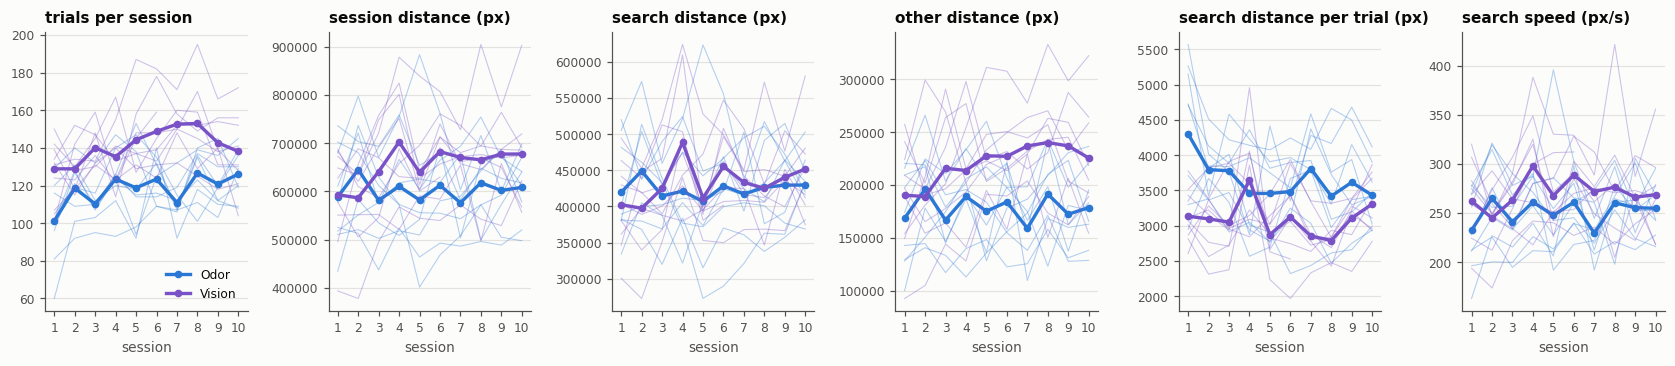

In [2]:
fig, axes = plt.subplots(1, 6, figsize=(19, 3.3), gridspec_kw={'wspace': 0.4})
for ax, col in zip(axes, ['trials', 'session_px', 'search_px', 'other_px', 'px_per_trial', 'px_per_s']):
    for exp in EXPERIMENTS:
        s = ses[ses.experiment == exp]
        for _, g in s.groupby('mouse'):
            ax.plot(g.session_num, g[col], color=EXP_COLOR[exp], lw=0.7, alpha=0.35)
        mean = s.groupby('session_num')[col].mean()
        ax.plot(mean.index, mean, color=EXP_COLOR[exp], lw=2.2, marker='o', ms=4, label=EXP_LABEL[exp])
    ax.set(title=MEASURES.get(col, 'trials per session'), xlabel='session', xticks=range(1, 11))
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend()
plt.show()

## 2. Regressing each measure on trials per session

For each measure and experiment, and for both experiments together (a mouse's odor and vision sessions centred separately):

- **within mouse**: each mouse's own least-squares slope across its sessions; mean across mice, t-test of that mean against zero, and how many mice have a positive slope. For the distances and path-shape measures the slope is an elasticity (log measure on log trials); for uniformity it is the change per 10 trials, as in `occupancy_uniformity.ipynb`.
- **r**: the within-mouse correlation (sessions centred on their mouse's mean, pooled), a unit-free size that can be compared across measures.
- **within mouse, + session number**: session number as a second predictor in each mouse's fit, to set aside improvement with experience.

In [3]:
def fit(y, X):
    """Least-squares coefficients of y on X (X without the intercept column)."""
    A = np.column_stack([np.ones(len(y)), X])
    return np.linalg.lstsq(A, y, rcond=None)[0][1:]

def centred(df, cols):
    """Each column minus its mean within mouse and experiment."""
    return df[cols] - df.groupby(['mouse', 'experiment'])[cols].transform('mean')

def prepared(df, col):
    """The outcome and predictors on the scale they are fitted on."""
    out = pd.DataFrame({'y': np.log(df[col]) if col in LOGGED else df[col],
                        'x': np.log(df.trials) if col in LOGGED else df.trials / 10,
                        'session_num': df.session_num, 'mouse': df.mouse, 'experiment': df.experiment}, index=df.index)
    out[['y', 'x', 'session_num']] = centred(out, ['y', 'x', 'session_num'])
    return out

def within(df, col):
    d = prepared(df, col)
    row = {'slope': 'elasticity' if col in LOGGED else 'per 10 trials', 'r': np.corrcoef(d.x, d.y)[0, 1]}
    for name, X in (('', ['x']), (', + session number', ['x', 'session_num'])):
        b = pd.Series({m: fit(g.y.to_numpy(), g[X].to_numpy())[0] for m, g in d.groupby('mouse')})
        row |= {f'mean slope{name}': b.mean(), f'sem{name}': b.sem(), f'p{name}': sps.ttest_1samp(b, 0).pvalue,
                f'mice positive{name}': f'{int((b > 0).sum())}/{len(b)}'}
    return row

GROUPS = {EXP_LABEL[e]: ses[ses.experiment == e] for e in EXPERIMENTS} | {'Both': ses}
results = pd.DataFrame({(MEASURES[col], g): within(df, col) for col in MEASURES for g, df in GROUPS.items()}).T
results.index.names = ['measure', 'sessions']
fmt = {c: '{:+.3f}' for c in results if c.startswith('mean slope')} | {c: '{:.3f}' for c in results if c.startswith('sem')} | \
      {c: '{:.4f}' for c in results if c.startswith('p')} | {'r': '{:+.2f}'}
results.style.format({k: v for k, v in fmt.items() if k in results}, na_rep='')

**The within-mouse relations, drawn.** Each session relative to its mouse's mean for that experiment: for the distances and path-shape measures, percent above or below the mouse's mean against percent more or fewer trials; for uniformity, the raw difference. Thin lines: each mouse's own fit. Thick line: the mean within-mouse slope. First the distances (with uniformity), then the path-shape measures.

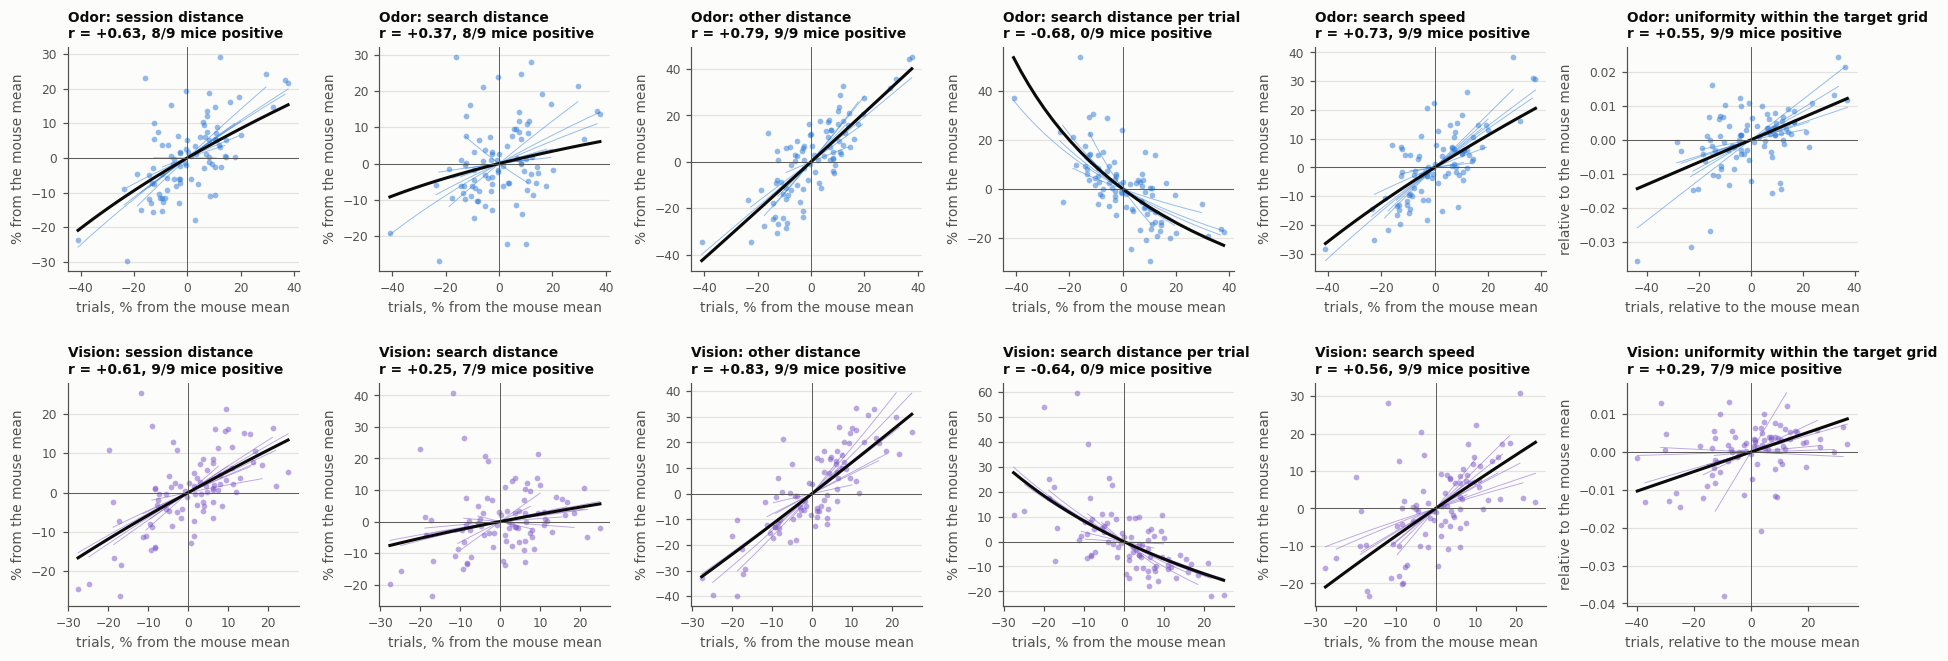

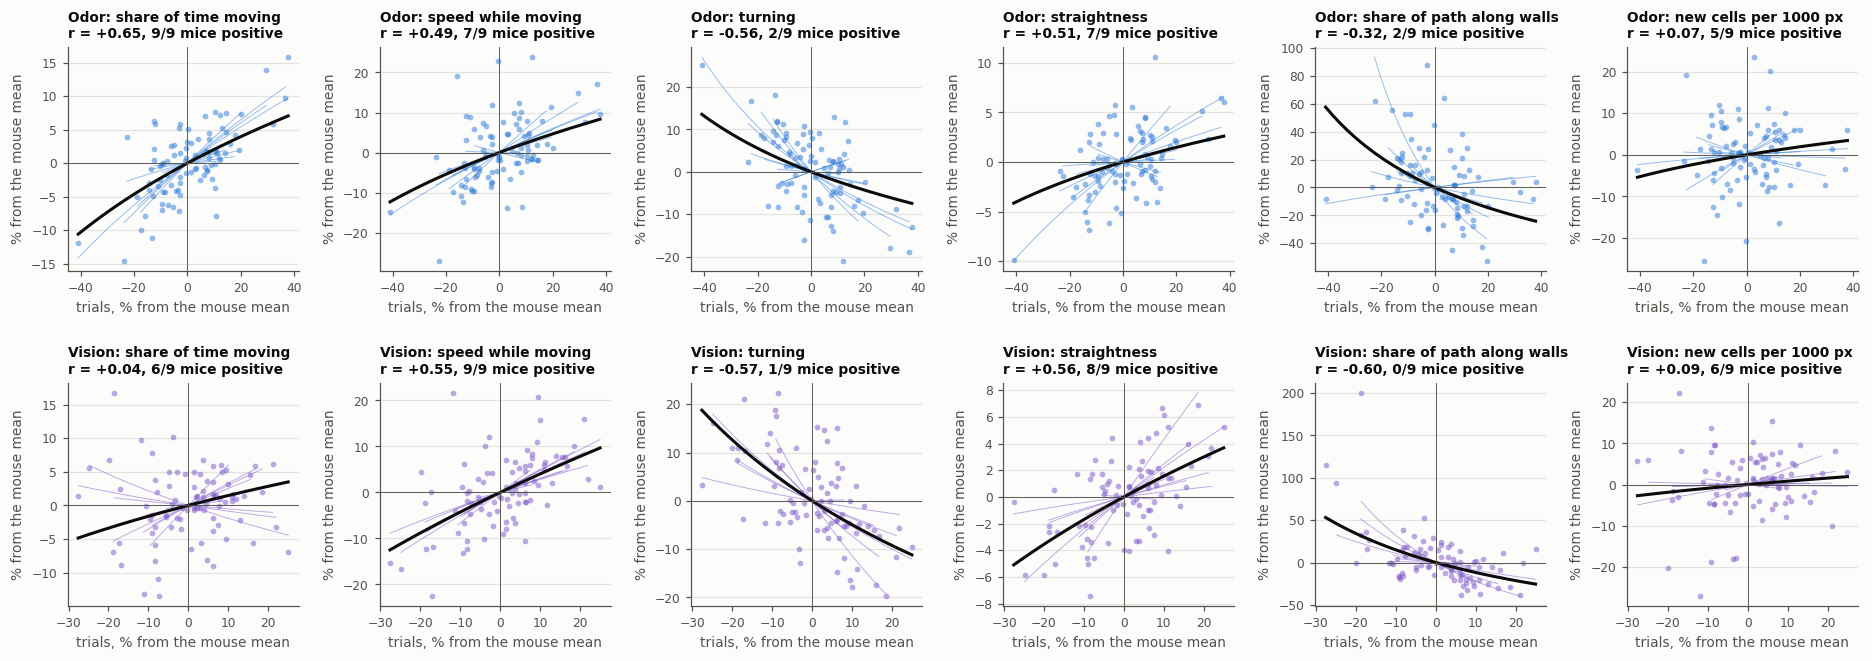

In [4]:
def within_figure(shown):
    fig, axes = plt.subplots(2, len(shown), figsize=(3.5 * len(shown), 6.6), gridspec_kw={'wspace': 0.35, 'hspace': 0.5})
    for row, exp in zip(axes, EXPERIMENTS):
        df = ses[ses.experiment == exp]
        for ax, col in zip(row, shown):
            d = prepared(df, col)
            to_pct = (lambda v: 100 * (np.exp(v) - 1)) if col in LOGGED else (lambda v: v)
            to_x = (lambda v: 100 * (np.exp(v) - 1)) if col in LOGGED else (lambda v: 10 * v)
            ax.scatter(to_x(d.x), to_pct(d.y), s=14, color=EXP_COLOR[exp], alpha=0.5, lw=0)
            slopes = []
            for m, g in d.groupby('mouse'):
                b = fit(g.y.to_numpy(), g[['x']].to_numpy())[0]
                slopes.append(b)
                xs = np.linspace(g.x.min(), g.x.max(), 20)
                ax.plot(to_x(xs), to_pct(b * xs), color=EXP_COLOR[exp], lw=0.6, alpha=0.5)
            xs = np.linspace(d.x.min(), d.x.max(), 20)
            ax.plot(to_x(xs), to_pct(np.mean(slopes) * xs), color=INK, lw=2)
            ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
            res = results.loc[(MEASURES[col], EXP_LABEL[exp])]
            ax.set_title(f"{EXP_LABEL[exp]}: {MEASURES[col].split(' (')[0]}\nr = {res.r:+.2f}, {res['mice positive']} mice positive", fontsize=9)
            ax.set(xlabel=('trials, % from the mouse mean' if col in LOGGED else 'trials, relative to the mouse mean'),
                   ylabel=('% from the mouse mean' if col in LOGGED else 'relative to the mouse mean'))
            ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
    plt.show()

within_figure(list(DISTANCE) + ['U_grid'])
within_figure(list(TRAJ))

## 3. How sensitive is each measure?

Two numbers per measure, both within mouse:

- **session-to-session spread**: the SD of the measure across a mouse's sessions, as a percent of its mean (for uniformity, relative to the range it can take, 1 - U). A measure that hardly varies between sessions cannot track anything.
- **r with trials** (from the table above), and how consistent the sign is across mice.

The chart ranks every measure by its within-mouse correlation with trials. Gray labels: measures tied to the trial count by construction (session distance, other distance, distance per trial), which say little about how the mouse searches.

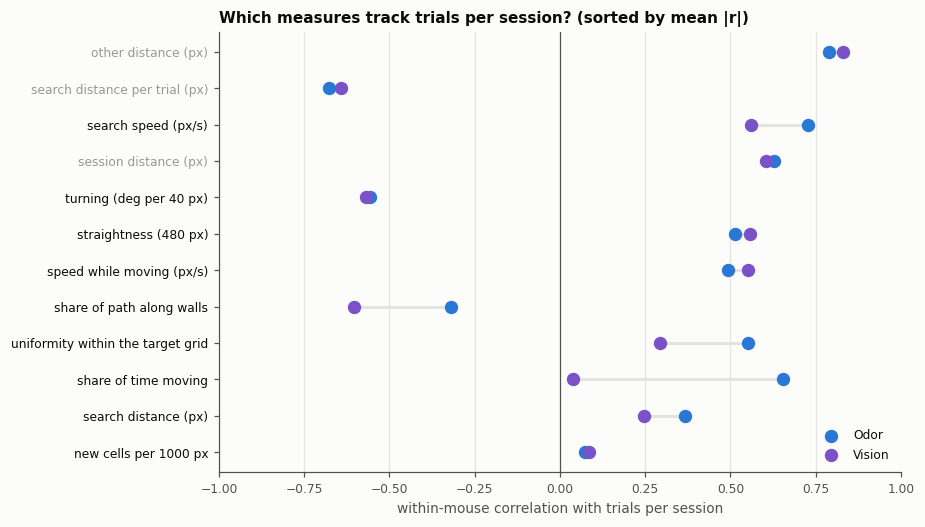

In [5]:
def spread(df, col):
    v = df[col] if col != 'U_grid' else 1 - df[col]             # uniformity: spread of the distance from perfect evenness
    return 100 * (v.groupby(df.mouse).std() / v.groupby(df.mouse).mean()).mean()

sens = pd.DataFrame({(MEASURES[col], EXP_LABEL[e]): {'session-to-session spread (% of mean)': spread(ses[ses.experiment == e], col),
                                                     'r with trials': results.loc[(MEASURES[col], EXP_LABEL[e]), 'r'],
                                                     'mice positive': results.loc[(MEASURES[col], EXP_LABEL[e]), 'mice positive']}
                     for col in MEASURES for e in EXPERIMENTS}).T
sens['session-to-session spread (% of mean)'] = sens['session-to-session spread (% of mean)'].astype(float)
sens['r with trials'] = sens['r with trials'].astype(float)

order = sorted(MEASURES, key=lambda c: -np.mean([abs(results.loc[(MEASURES[c], EXP_LABEL[e]), 'r']) for e in EXPERIMENTS]))
fig, ax = plt.subplots(figsize=(8, 5.2))
for k, col in enumerate(order):
    rs = [results.loc[(MEASURES[col], EXP_LABEL[e]), 'r'] for e in EXPERIMENTS]
    ax.plot(rs, [k, k], color=GRID, lw=2, zorder=1)
    for e, r in zip(EXPERIMENTS, rs):
        ax.scatter(r, k, s=60, color=EXP_COLOR[e], zorder=3, label=EXP_LABEL[e] if k == 0 else None)
ax.set_yticks(range(len(order)), [MEASURES[c] for c in order])
for label, col in zip(ax.get_yticklabels(), order):
    label.set_color('#9a9893' if col in BUILT_IN else INK)
ax.invert_yaxis(); ax.axvline(0, color=MUTED, lw=0.8)
ax.set(xlim=(-1, 1), xlabel='within-mouse correlation with trials per session')
ax.set_title('Which measures track trials per session? (sorted by mean |r|)')
ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(loc='lower right')
plt.show()
sens.style.format({'session-to-session spread (% of mean)': '{:.1f}', 'r with trials': '{:+.2f}'})

## Summary

**Distance over the whole session tracks trials closely, but mostly by construction.**
- Session distance rises with trials within every mouse (r = 0.63 in odor, 0.61 in vision; elasticity 0.45 and 0.56).
- Most of that is the distance covered outside searching, which grows one for one with trials (elasticity 1.05 in odor, 1.21 in vision; r = 0.79 and 0.83, 9/9 mice). Every trial adds a walk to the port and back, so this part counts trials rather than measuring how the mouse searches.

**Distance while searching barely moves.** A session with 10% more trials has about 2% more search distance (elasticity 0.18 in odor, 0.24 in vision; r = 0.37 and 0.25), not significant in either experiment alone (p = 0.12, 0.08), and with session number in the fit the vision slope is zero. Search distance is nearly the same from session to session, so in a good session the extra targets come from the same ground: the path per trial falls almost as fast as the trials rise (elasticity -0.82 and -0.76). That ratio is close to circular, since it divides a nearly constant distance by the trial count.

**What does move is speed.** Search distance stays put while search time shrinks (more of the fixed session goes to retrieving and drinking), so the mouse is covering the same ground faster. Search speed rises with trials in every mouse in both experiments (elasticity 0.58 in odor, 0.73 in vision; r = 0.73 and 0.56, 9/9 and 9/9), and keeps most of that with session number in the fit (0.59 and 0.55). This matches `search_trajectories.ipynb`: a good session is a more vigorous one.

**The path-shape measures.** Phase-matched, so a session with few trials is not penalised for having more long searches:
- *Speed while moving* rises with trials (r = 0.49 in odor, 0.55 in vision; 7/9 and 9/9 mice), and keeps it with session number in the fit.
- *Turning* falls and *straightness* rises (r = -0.56 and -0.57; +0.51 and +0.56). Turning is lower in a good session in 7/9 mice in odor and 8/9 in vision. These go with speed: `search_trajectories.ipynb` found turning and speed nearly the same axis (r = -0.81).
- *Share of time moving* tracks trials in odor (r = 0.65, 9/9 mice) but not in vision (0.04, 6/9), as in `search_trajectories.ipynb`. With session number in the fit the odor slope halves (p = 0.14), so part of it is the early sessions, when pausing falls as mice learn the task.
- *Wall-following* falls in good sessions, more clearly in vision (r = -0.60, lower in 9/9 mice) than in odor (-0.32, 7/9). It is also the measure with the largest session-to-session spread (22-28%).
- *Yield*, new cells per 1000 px, does not track trials at all (r = 0.07 and 0.09). A good session covers ground faster, not more efficiently.

**Ranking.** Of the measures not tied to the trial count by construction, **search speed** tracks trials best in odor (r = 0.73) and is among the best in vision (0.56, 9/9 mice). Wall-following, turning, straightness and speed while moving do about as well in vision (|r| = 0.55-0.60) and only somewhat less in odor. Uniformity sits in the middle (0.55 and 0.29), with search distance and yield at the bottom. The spread column is not a fair comparison for uniformity: its 31-33% is the spread of 1 - U, its distance from perfect evenness, which says that the index varies a good deal between sessions once it is read on that scale, even though U itself looks compressed near 1.

**Reading the results.**
- Correlation only: a motivated mouse may run faster and so find more, or quick finds may keep it running.
- Speed and trials share a denominator in spirit: both are rates over a fixed-length session. Speed is distance per second of *search*, and trials are not counted in it, but anything that changes how much of the session is spent searching affects both.
- The path-shape measures move together (speed, turning and straightness are close to one axis), so their correlations with trials are not independent pieces of evidence.
- r here is the correlation of sessions centred on their mouse's mean, pooled over mice; `search_trajectories.ipynb` averages one correlation per mouse instead, so the two notebooks' values differ slightly.
- Distances are on the SLEAP body centroid in camera pixels; uniformity is on the nose. Yield is counted with the task's own point. p-values are unadjusted, and there are many of them.